<a href="https://colab.research.google.com/github/fxrdhan/Practical-Statistics-for-Data-Scientists/blob/main/Chapter_04_Regression_and_Prediction/Chapter_04_Regression_and_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 4 — Regression and Prediction

| | |
|---|---|
| **Book** | *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, 2nd edition — Peter Bruce, Andrew Bruce and Peter Gedeck (O'Reilly Media, 2020) |
| **Code reproduced here** | the Python code of the book's official repository, `gedeck/practical-statistics-for-data-scientists` (GNU General Public License v3) |
| **Versions used to run this notebook** | printed by the setup cell |
| **What this notebook contains** | a summary of every section of the chapter, the theory behind it, the book's Python code reproduced and executed, and a short analysis of the outputs |

## Chapter overview

Regression is the workhorse of prediction: it models an outcome (the response) as a function of one or more predictors, so that the outcome can be predicted for new data and the role of each predictor can be explained. The chapter starts with **simple linear regression** (one predictor), moves to **multiple linear regression** (many predictors, the King County house prices), and then covers what is needed to use a regression well: **prediction** with its intervals, **factor (categorical) variables**, the **interpretation** of coefficients (correlated predictors, confounding, interactions), **diagnostics** (outliers, influential observations, the assumptions about the errors) and **nonlinear** extensions (polynomial and spline regression, generalized additive models). The official code ends with additional material on regularization (the lasso), which is also reproduced here.

### Sections of this chapter

| # | Section of the book | Python code in the book |
|---|---|---|
| 1 | Simple linear regression | lung disease data: fit, fitted values and residuals |
| 2 | Multiple linear regression | house prices: scikit-learn and statsmodels fits, full model, stepwise selection, weighted regression |
| 3 | Prediction using regression | no code |
| 4 | Factor variables in regression | dummy variables, a factor with many levels (zip codes) |
| 5 | Interpreting the regression equation | correlated predictors, confounding, interactions |
| 6 | Regression diagnostics | outliers, influential values, heteroskedasticity, partial residual plots |
| 7 | Polynomial and spline regression | polynomial, spline, generalized additive model |
| 8 | Additional material of the official repository (not in the book): regularization | the lasso |

### How to read this notebook

Every section has the same structure: a **Summary** (what the book says, condensed in my own words; the book itself is not quoted), the **Theory** behind the section, the **Book code** (the official Python code of the chapter, reproduced and executed) and a short **Output analysis**.

Every code cell starts with a label comment: `# BOOK CODE` for code of the official repository (the setup cell is labelled `# SETUP` and is not part of the book). The book's code is reproduced as it is; where it needs a change to run on current library versions, the change is marked in the cell with `# CHANGED` and explained in the text.

---
## 0. Setup

The datasets of the book live in the official repository, in its `data` folder. The helper `ensure_data` below looks for each file in a folder called `data` next to the notebook and **downloads it from the official repository the first time** it is missing (this is the only use of the network; the folder is not part of this repository, see `.gitignore`). The two files of this chapter are `LungDisease.csv` (the lung capacity and the exposure of 122 workers) and `house_sales.csv` (22,687 house sales in King County, tab-separated).

The setup cell also prints the versions of the libraries, because the code of the book was written for older ones. Two libraries that the chapter needs are not part of a standard Python installation: `pygam` (generalized additive models) and `dmba` (the stepwise selection of the book's authors); the cell installs them if they are missing (a fresh environment, or Google Colab, may not have them).

In [1]:
# SETUP
import importlib.util
import platform
import subprocess
import sys
import urllib.request
import warnings
from pathlib import Path

# a fresh environment may not have `pygam` (section 7) and `dmba` (section 2); install them when they are missing
for module, package in (("pygam", "pygam"), ("dmba", "dmba")):
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import sklearn
import statsmodels
import pygam

print(f"Python       : {platform.python_version()}")
print(f"NumPy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"statsmodels  : {statsmodels.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"pygam        : {pygam.__version__}")
print(f"seaborn      : {sns.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# print warnings without the file path, so that the saved output does not depend on the machine
warnings.formatwarning = lambda message, category, filename, lineno, line=None: f"{category.__name__}: {message}\n"

# --- the datasets of the official repository ---------------------------------------------------------
DATA = Path("data")
DATA_URL = "https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data/"


def ensure_data(*names):
    """Make sure that the files `names` exist in the folder `data`; download the missing ones."""
    DATA.mkdir(exist_ok=True)
    for name in names:
        if not (DATA / name).exists():
            urllib.request.urlretrieve(DATA_URL + name, DATA / name)
    return DATA


ensure_data("LungDisease.csv", "house_sales.csv")

# --- a quiet, colour-blind-safe style (global: it also applies to the figures of the book code) --------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua (checked for colour-vision deficiency)
INK, INK_SOFT, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_SOFT, "axes.labelsize": 10,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK_SOFT,
    "figure.dpi": 110, "font.size": 10,
})

Python       : 3.12.3
NumPy        : 2.5.4
pandas       : 3.1.0
SciPy        : 1.16.3
statsmodels  : 0.15.0
scikit-learn : 1.9.1
pygam        : 0.12.0
seaborn      : 0.13.2
Matplotlib   : 3.11.2


The imports and the paths of the official script follow (the official script finds its data folder with a helper module; here `DATA` comes from the setup cell). The module `pygam.datasets` also provides the `wage` data set, which the script imports but does not use.

In [2]:
# BOOK CODE (imports and paths of the official script; `DATA` comes from the setup cell of this notebook)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, LassoLars, LassoCV, LassoLarsCV
from scipy.stats import linregress
from pathlib import Path

import pandas as pd
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.linear_model import LinearRegression

import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import OLSInfluence

from pygam import LinearGAM, s, l
from pygam.datasets import wage


import seaborn as sns
import matplotlib.pyplot as plt

from dmba import stepwise_selection
from dmba import AIC_score

# Define paths to data sets. If you don't keep your data in the same directory as the code, adapt the path names.

LUNG_CSV = DATA / 'LungDisease.csv'
HOUSE_CSV = DATA / 'house_sales.csv'

no display found. Using non-interactive Agg backend


Importing `dmba` has a side effect: when it finds no display (a server, or a notebook run in the background) it prints a message and switches Matplotlib to the non-interactive `Agg` backend, and then no figure appears in the notebook. The next cell is not part of the book; it switches the figures of the notebook on again.

In [3]:
# SETUP (continued; not in the book): show the figures in the notebook although `dmba` may have selected the Agg backend
%matplotlib inline

---
## 1. Simple linear regression

*Book section: "Simple Linear Regression" (the regression equation, fitted values and residuals, least squares, prediction versus explanation). The code of the script fits the lung capacity of workers to the years of exposure to cotton dust.*

### Summary

* **Simple linear regression** models the relationship between a **response** $Y$ (the variable to predict) and one **predictor** $X$ by a straight line: as $X$ grows by one unit, $Y$ changes on average by the slope. It differs from **correlation**, which only measures how strongly the two variables are related; regression quantifies the *nature* of the relationship.
* The **regression equation** is $\hat Y = b_0 + b_1 X$. The **intercept** $b_0$ is the predicted value when $X = 0$ and the **slope** $b_1$ is the predicted change in $Y$ per unit of $X$ (the regression coefficients).
* The **fitted values** $\hat Y_i$ are the predictions of the line for the observed data, and the **residuals** $e_i = Y_i - \hat Y_i$ are the vertical distances of the data from the line.
* The line is found by **least squares**: the coefficients minimize the sum of the squared residuals. Least squares is the standard because it is easy to compute and it is the best linear unbiased estimate under the usual assumptions; it is sensitive to outliers, because errors are squared.
* Regression is used in two ways. In **prediction** the aim is to forecast the outcome for new records; in **explanation (profiling)** the aim is to understand the relationship between the predictors and the outcome, where the coefficients are the object of interest. The data scientist's emphasis is on prediction.
* The example of the script: the peak expiratory flow rate (PEFR) of 122 cotton workers against the years of exposure. The fitted line has an intercept of 424.6 and a slope of -4.19: on average 4.19 units of PEFR are lost per year of exposure.

### Theory

**The model and its least-squares solution.** The model is $y_i = \beta_0 + \beta_1 x_i + \varepsilon_i$ with errors $\varepsilon_i$ of mean 0 and variance $\sigma^2$. Least squares minimizes the residual sum of squares
$$\mathrm{RSS}(b_0, b_1) = \sum_{i=1}^n (y_i - b_0 - b_1 x_i)^2 .$$
Setting the derivatives to zero gives the solution
$$b_1 = \frac{\sum_i (x_i - \bar x)(y_i - \bar y)}{\sum_i (x_i - \bar x)^2} = r\,\frac{s_y}{s_x}, \qquad b_0 = \bar y - b_1 \bar x,$$
where $r$ is the correlation and $s_x, s_y$ are the standard deviations. The line always passes through the point of the means $(\bar x, \bar y)$, the residuals sum to zero, and they are uncorrelated with $x$.

**Measures of fit.** The **residual standard error** (the typical size of a residual) is $\sqrt{\mathrm{RSS}/(n-2)}$, with $n - 2$ degrees of freedom because two coefficients were estimated; the **root mean squared error** is $\mathrm{RMSE} = \sqrt{\mathrm{RSS}/n}$. The **coefficient of determination** $R^2 = 1 - \mathrm{RSS}/\mathrm{TSS}$ is the share of the variation of $Y$ explained by the model, where $\mathrm{TSS} = \sum (y_i - \bar y)^2$; for one predictor it equals $r^2$.

**The slope is a statistic.** The estimated slope varies from sample to sample, with the standard error $\sigma/\sqrt{\sum (x_i - \bar x)^2}$ (estimated by replacing $\sigma$ with the residual standard error). The ratio $b_1/\mathrm{se}(b_1)$ is the $t$ statistic used to test whether the true slope is zero.

### Book code

The script reads the data and draws a scatterplot of the exposure (in years) against the PEFR.

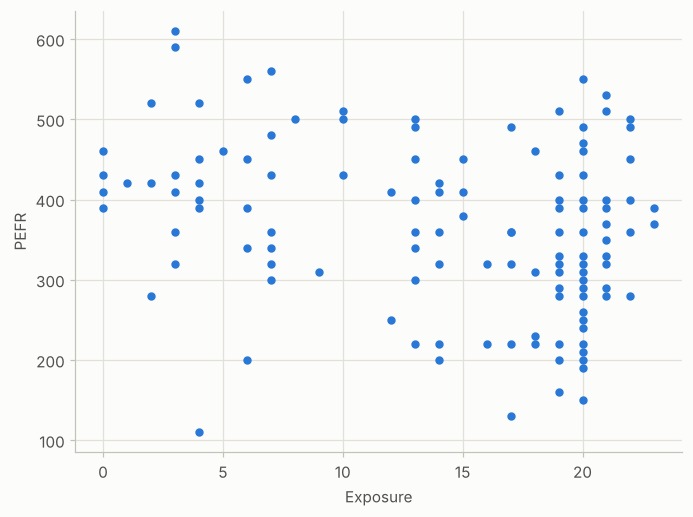

In [4]:
# BOOK CODE (Simple Linear Regression): the lung disease data
lung = pd.read_csv(LUNG_CSV)

lung.plot.scatter(x='Exposure', y='PEFR')

plt.tight_layout()
plt.show()

The model is fitted with the `LinearRegression` class of scikit-learn.

In [5]:
# BOOK CODE (The Regression Equation): the fitted line
predictors = ['Exposure']
outcome = 'PEFR'

model = LinearRegression()
model.fit(lung[predictors], lung[outcome])

print(f'Intercept: {model.intercept_:.3f}')
print(f'Coefficient Exposure: {model.coef_[0]:.3f}')

Intercept: 424.583
Coefficient Exposure: -4.185


The figure of the book explains the equation: the intercept $b_0$, and the slope $b_1 = \Delta Y / \Delta X$ read from two points of the line.

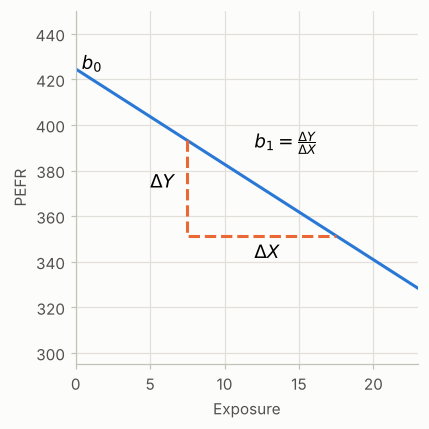

In [6]:
# BOOK CODE (The Regression Equation): the line with intercept and slope
fig, ax = plt.subplots(figsize=(4, 4))
ax.set_xlim(0, 23)
ax.set_ylim(295, 450)
ax.set_xlabel('Exposure')
ax.set_ylabel('PEFR')
ax.plot((0, 23), model.predict(pd.DataFrame({'Exposure': [0, 23]})))
ax.text(0.4, model.intercept_, r'$b_0$', size='larger')

x = pd.DataFrame({'Exposure': [7.5, 17.5]})
y = model.predict(x)
ax.plot((7.5, 7.5, 17.5), (y[0], y[1], y[1]), '--')
ax.text(5, np.mean(y), r'$\Delta Y$', size='larger')
ax.text(12, y[1] - 10, r'$\Delta X$', size='larger')
ax.text(12, 390, r'$b_1 = \frac{\Delta Y}{\Delta X}$', size='larger')

plt.tight_layout()
plt.show()

The method `predict` gives the fitted values; the residuals are the differences from the data, drawn as dashed segments.

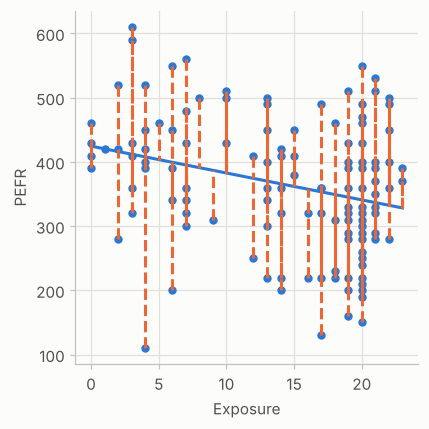

In [7]:
# BOOK CODE (Fitted Values and Residuals): the fitted values and the residuals
fitted = model.predict(lung[predictors])
residuals = lung[outcome] - fitted

ax = lung.plot.scatter(x='Exposure', y='PEFR', figsize=(4, 4))
ax.plot(lung.Exposure, fitted)
for x, yactual, yfitted in zip(lung.Exposure, lung.PEFR, fitted):
    ax.plot((x, x), (yactual, yfitted), '--', color='C1')

plt.tight_layout()
plt.show()

**Output analysis.**

* **The scatterplot.** The 122 workers have between 0 and 23 years of exposure. The PEFR values are widely scattered (from about 110 to 610) at every level of exposure, with a weak downward tendency: the relationship is not tight.
* **The fitted line.** The intercept is 424.583 and the slope -4.185: for a worker with no exposure the line predicts a PEFR of about 424.6, and each additional year of exposure goes with a PEFR that is 4.185 units lower on average (at 23 years the line is at about 328). This describes an association in these data; it does not by itself show that the exposure caused the loss.
* **The annotated figure** shows how the slope is read: between the exposures 7.5 and 17.5 the line falls by $\Delta Y$, and the slope is $\Delta Y/\Delta X$.
* **The residuals.** The dashed segments are the residuals. They are long and of both signs, a few of them around 200 to 300 units, which shows that the line explains only part of the variation of the PEFR between workers.

---
## 2. Multiple linear regression

*Book section: "Multiple Linear Regression" (example: King County housing data, assessing the model, cross-validation, model selection and stepwise regression, weighted regression). The code of the script predicts house prices from the size, the grade and other features of 22,687 sales.*

### Summary

* **Multiple linear regression** extends the simple model to several predictors: $\hat Y = b_0 + b_1X_1 + \dots + b_pX_p$. Each coefficient is the expected change of the response per unit of its predictor *with the other predictors held fixed*.
* The example is the **King County (Seattle) housing data**: the response is the sale price (adjusted for the market level, `AdjSalePrice`), the predictors are the living area (`SqFtTotLiving`), the lot size (`SqFtLot`), the numbers of bathrooms and bedrooms, and the building grade (`BldgGrade`). The fitted model explains about 54% of the variance and has a root mean squared error of about 261,000 dollars.
* **Assessing the model:** the RMSE and the residual standard error describe the size of the errors; the **R-squared** is the share of variance explained (the *adjusted* R-squared penalizes the number of predictors); the **t-statistic** of a coefficient (the estimate divided by its standard error) and its p-value show whether the predictor adds information to the others. `statsmodels` prints all of them in one summary table.
* **Cross-validation** estimates the error on *new* data: the data are split into $k$ folds, the model is fitted $k$ times on $k-1$ folds and evaluated on the fold left out. Measures computed on the training data alone are optimistic and, with many predictors, misleading. (The script has no code for this part.)
* **Model selection:** adding a predictor always lowers the training error, but it can make the prediction on new data worse (overfitting). The principle of **parsimony** says to prefer the simplest model that works. Criteria such as the **AIC** penalize the number of coefficients. **Stepwise regression** adds (forward) or removes (backward) predictors one at a time as long as the criterion improves; the all-subsets search is the exhaustive alternative. The script uses the stepwise function of the `dmba` package with the AIC.
* **Weighted regression** gives each record a weight in the least squares criterion. It is used when the records differ in precision, or to give more importance to some of them. In the example, the sales are weighted by how recent they are (the year minus 2005), so that the model pays more attention to recent sales.

### Theory

**Matrix form and the least squares solution.** With the design matrix $X$ ($n$ rows, a column of ones and the $p$ predictors) the model is $y = X\beta + \varepsilon$, and the least squares estimate is
$$\hat\beta = (X^\top X)^{-1} X^\top y,$$
with the covariance matrix $\widehat{\operatorname{Var}}(\hat\beta) = \hat\sigma^2 (X^\top X)^{-1}$ and $\hat\sigma^2 = \mathrm{RSS}/(n - p - 1)$. The standard error of a coefficient is the square root of the corresponding diagonal element, and $t_j = \hat\beta_j/\mathrm{se}(\hat\beta_j)$ has $n-p-1$ degrees of freedom.

**R-squared and the $F$ test.** $R^2 = 1 - \mathrm{RSS}/\mathrm{TSS}$; the adjusted version is $1 - (1-R^2)\frac{n-1}{n-p-1}$. The overall $F$-statistic, $F = \dfrac{(\mathrm{TSS}-\mathrm{RSS})/p}{\mathrm{RSS}/(n-p-1)}$, tests that all coefficients are zero.

**Information criteria.** For a Gaussian model with log-likelihood $\ell$ and $k$ estimated parameters, $\mathrm{AIC} = 2k - 2\ell$ and $\mathrm{BIC} = k\ln n - 2\ell$; smaller is better, and the BIC penalizes the number of parameters more strongly for $n > 7$.

**Cross-validation.** The $k$-fold estimate of the prediction error is the average over the folds of the error on the fold that was not used for fitting. With $k = n$ it is leave-one-out cross-validation.

**Weighted least squares.** Minimizing $\sum_i w_i (y_i - x_i^\top b)^2$ gives $\hat\beta_w = (X^\top W X)^{-1}X^\top W y$ with $W = \operatorname{diag}(w_i)$. With weights proportional to the inverse of the error variance of each record it is the most efficient linear unbiased estimate.

### Book code

The script reads the house data (the file is tab-separated) and shows the first rows of the variables that it uses.

In [8]:
# BOOK CODE (Multiple Linear Regression): the King County housing data
subset = ['AdjSalePrice', 'SqFtTotLiving', 'SqFtLot', 'Bathrooms',
          'Bedrooms', 'BldgGrade']

house = pd.read_csv(HOUSE_CSV, sep='\t')
print(house[subset].head())

   AdjSalePrice  SqFtTotLiving  SqFtLot  Bathrooms  Bedrooms  BldgGrade
1      300805.0           2400     9373       3.00         6          7
2     1076162.0           3764    20156       3.75         4         10
3      761805.0           2060    26036       1.75         4          8
4      442065.0           3200     8618       3.75         5          7
5      297065.0           1720     8620       1.75         4          7


The model with five predictors, fitted with scikit-learn.

In [9]:
# BOOK CODE (Multiple Linear Regression): the model with five predictors
predictors = ['SqFtTotLiving', 'SqFtLot', 'Bathrooms',
              'Bedrooms', 'BldgGrade']
outcome = 'AdjSalePrice'

house_lm = LinearRegression()
house_lm.fit(house[predictors], house[outcome])

print(f'Intercept: {house_lm.intercept_:.3f}')
print('Coefficients:')
for name, coef in zip(predictors, house_lm.coef_):
    print(f' {name}: {coef}')

Intercept: -521871.368
Coefficients:
 SqFtTotLiving: 228.83060360240785
 SqFtLot: -0.06046682065307074
 Bathrooms: -19442.840398320997
 Bedrooms: -47769.9551852143
 BldgGrade: 106106.9630789808


Assessing the model with the RMSE and the R-squared of scikit-learn.

In [10]:
# BOOK CODE (Assessing the Model): RMSE and R-squared
fitted = house_lm.predict(house[predictors])
RMSE = np.sqrt(mean_squared_error(house[outcome], fitted))
r2 = r2_score(house[outcome], fitted)
print(f'RMSE: {RMSE:.0f}')
print(f'r2: {r2:.4f}')

RMSE: 261220
r2: 0.5406


`statsmodels` gives a more detailed analysis. As it does not add an intercept automatically, the script adds a column of ones with `assign`.

In [11]:
# BOOK CODE (Assessing the Model): the statsmodels summary
model = sm.OLS(house[outcome], house[predictors].assign(const=1))
results = model.fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:           AdjSalePrice   R-squared:                       0.541
Model:                            OLS   Adj. R-squared:                  0.540
Method:                 Least Squares   F-statistic:                     5338.
Date:                Sat, 24 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:44:32   Log-Likelihood:            -3.1517e+05
No. Observations:               22687   AIC:                         6.304e+05
Df Residuals:                   22681   BIC:                         6.304e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
SqFtTotLiving   228.8306      3.899     58.694

**Output analysis of the first model.**

* **The coefficients (scikit-learn).** With the other predictors held fixed, one more square foot of living area goes with a price that is 228.83 dollars higher, and one more building grade with a price that is 106,107 dollars higher. The lot size has a coefficient close to zero (-0.06 dollars per square foot). The coefficients of the bathrooms (-19,443) and of the bedrooms (-47,770) are *negative*: they do not say that bathrooms and bedrooms reduce the value of a house, but that, given the living area, a house with more of them is on average cheaper; section 5 comes back to this.
* **RMSE and R-squared.** The RMSE is 261,220 dollars and the R-squared 0.5406: the model explains about 54% of the variance of the prices, and a typical prediction error is about 261,000 dollars. Both are computed on the data used to fit the model, so they are optimistic as a measure of the error for new sales (cross-validation of section 2 estimates that).
* **The `statsmodels` summary** gives the same coefficients with their standard errors, $t$ statistics and intervals. All of them are significant except the lot size ($p = 0.323$); the $t$ values of the four significant predictors range from -19.2 (bedrooms) to 58.7 (living area). The R-squared is 0.541 and the adjusted R-squared 0.540, the same here because there are 22,687 records and only five predictors.
* **Warnings in the table.** The condition number is large (2.86e+05), because the predictors are on very different scales; the Jarque-Bera test, a skewness of 6.9 and a kurtosis of 145.6 show that the residuals are very far from normal (a heavy right tail of very expensive houses), which is taken up in section 6. The Durbin-Watson statistic of 1.25 is below 2, but it depends on the order of the rows in the file, which has no meaning here.

For the model selection the script uses more predictors, among them the categorical `PropertyType`, which `pd.get_dummies` turns into indicator columns (section 4). The full model first.

In [12]:
# BOOK CODE (Model Selection and Stepwise Regression): the full model
predictors = ['SqFtTotLiving', 'SqFtLot', 'Bathrooms', 'Bedrooms',
              'BldgGrade', 'PropertyType', 'NbrLivingUnits',
              'SqFtFinBasement', 'YrBuilt', 'YrRenovated',
              'NewConstruction']

X = pd.get_dummies(house[predictors], drop_first=True, dtype=int)
X['NewConstruction'] = [1 if nc else 0 for nc in X['NewConstruction']]

house_full = sm.OLS(house[outcome], X.assign(const=1))
results = house_full.fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:           AdjSalePrice   R-squared:                       0.595
Model:                            OLS   Adj. R-squared:                  0.594
Method:                 Least Squares   F-statistic:                     2771.
Date:                Sat, 24 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:44:32   Log-Likelihood:            -3.1375e+05
No. Observations:               22687   AIC:                         6.275e+05
Df Residuals:                   22674   BIC:                         6.276e+05
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
SqFtTotLiving       

The function `stepwise_selection` of the `dmba` package takes the candidate variables, a function that trains a model and a function that scores it (here the AIC) and adds, or removes, one variable at a time.

In [13]:
# BOOK CODE (Model Selection and Stepwise Regression): stepwise selection by the AIC
y = house[outcome]


def train_model(variables):
    if len(variables) == 0:
        return None
    model = LinearRegression()
    model.fit(X[variables], y)
    return model


def score_model(model, variables):
    if len(variables) == 0:
        return AIC_score(y, [y.mean()] * len(y), model, df=1)
    return AIC_score(y, model.predict(X[variables]), model)


best_model, best_variables = stepwise_selection(X.columns, train_model, score_model,
                                                verbose=True)

print()
print(f'Intercept: {best_model.intercept_:.3f}')
print('Coefficients:')
for name, coef in zip(best_variables, best_model.coef_):
    print(f' {name}: {coef}')

Variables: SqFtTotLiving, SqFtLot, Bathrooms, Bedrooms, BldgGrade, NbrLivingUnits, SqFtFinBasement, YrBuilt, YrRenovated, NewConstruction, PropertyType_Single Family, PropertyType_Townhouse
Start: score=647988.32, constant
Step: score=633013.35, add SqFtTotLiving
Step: score=630793.74, add BldgGrade
Step: score=628230.29, add YrBuilt
Step: score=627784.16, add Bedrooms
Step: score=627602.21, add Bathrooms
Step: score=627525.65, add PropertyType_Townhouse
Step: score=627525.08, add SqFtFinBasement
Step: score=627524.98, add PropertyType_Single Family
Step: score=627524.98, unchanged None

Intercept: 6178645.017
Coefficients:
 SqFtTotLiving: 199.27755304201577
 BldgGrade: 137159.5602262002
 YrBuilt: -3565.4249392493207
 Bedrooms: -51947.3836736137
 Bathrooms: 42396.1645277189
 PropertyType_Townhouse: 84479.16203300121
 SqFtFinBasement: 7.046974967572493
 PropertyType_Single Family: 22912.055187017613


**Output analysis of the model selection.**

* **The full model.** With twelve columns (the property type has two dummy columns) the R-squared rises to 0.595 and the AIC falls from 6.304e+05 to 6.275e+05. Some of the new variables are significant (the year built with -3,574 dollars per year, the property type townhouse), others are not: the number of living units ($p = 0.744$), the year of renovation ($p = 0.519$), new construction ($p = 0.675$), the lot size ($p = 0.184$) and the finished basement ($p = 0.127$). The negative coefficient of the year built means that, with the size and the grade held fixed, older houses sell for more in these data; a plausible reason is where the older houses are (confounding, section 5).
* **The stepwise selection.** The search starts from the constant model (AIC 647,988) and adds one variable per step: the living area (the AIC falls to 633,013), the grade (630,794), the year built (628,230), the bedrooms (627,784), the bathrooms (627,602), the townhouse indicator (627,526), the finished basement (627,525.08) and the single-family indicator (627,524.98); the last line says that nothing more improves the criterion. Most of the improvement comes in the first three steps; the last two each lower the AIC by less than 0.6. The variables that are never added are the lot size, the number of living units, the year of renovation and new construction.
* **The selected model** has eight columns; its coefficients are close to those of the full model (for example 199.28 dollars per square foot of living area, against 198.64). The AIC keeps the finished basement and the single-family indicator, which have large p-values in the full model, because the AIC accepts any addition that lowers it, which is a less strict rule than a p-value below 0.05.

For the weighted regression the script computes the year of each sale from its date and uses `Year - 2005` as the weight (recent sales weigh more).

In [14]:
# BOOK CODE (Weighted Regression): the weights
# We can calculate the Year from the date column using either a list comprehension or the data frame's `apply` method.
house['Year'] = [int(date.split('-')[0]) for date in house.DocumentDate]
house['Year'] = house.DocumentDate.apply(lambda d: int(d.split('-')[0]))
house['Weight'] = house.Year - 2005

In [15]:
# BOOK CODE (Weighted Regression): the weighted fit against the unweighted one
predictors = ['SqFtTotLiving', 'SqFtLot', 'Bathrooms',
              'Bedrooms', 'BldgGrade']
outcome = 'AdjSalePrice'

house_wt = LinearRegression()
house_wt.fit(house[predictors], house[outcome], sample_weight=house.Weight)

pd.concat([
    pd.DataFrame({
        'predictor': predictors,
        'house_lm': house_lm.coef_,
        'house_wt': house_wt.coef_,
    }),
    pd.DataFrame({
        'predictor': ['intercept'],
        'house_lm': house_lm.intercept_,
        'house_wt': house_wt.intercept_,
    })
])

,predictor,house_lm,house_wt
0,SqFtTotLiving,228.830604,245.024089
1,SqFtLot,-0.060467,-0.292415
2,Bathrooms,-19442.840398,-26085.970109
3,Bedrooms,-47769.955185,-53608.876436
4,BldgGrade,106106.963079,115242.434726
0,intercept,-521871.368188,-584189.329446


The script compares the absolute residuals of the two fits and averages them by year (a line that draws the boxplot of them is commented out in the script).

In [16]:
# BOOK CODE (Weighted Regression): the residuals of the two fits by year
residuals = pd.DataFrame({
    'abs_residual_lm': np.abs(house_lm.predict(house[predictors]) - house[outcome]),
    'abs_residual_wt': np.abs(house_wt.predict(house[predictors]) - house[outcome]),
    'Year': house['Year'],
})
print(residuals.head())
# axes = residuals.boxplot(['abs_residual_lm', 'abs_residual_wt'], by='Year', figsize=(10, 4))
# axes[0].set_ylim(0, 300000)

pd.DataFrame(([year, np.mean(group['abs_residual_lm']), np.mean(group['abs_residual_wt'])]
              for year, group in residuals.groupby('Year')),
             columns=['Year', 'mean abs_residual_lm', 'mean abs_residual_wt'])
# for year, group in residuals.groupby('Year'):
#     print(year, np.mean(group['abs_residual_lm']), np.mean(group['abs_residual_wt']))

   abs_residual_lm  abs_residual_wt  Year
1    123750.814194    107108.553965  2014
2     59145.413089     96191.882094  2006
3    190108.725716    187004.492880  2007
4    198788.774412    196132.996857  2008
5     91774.996129     84277.577512  2013


,Year,mean abs_residual_lm,mean abs_residual_wt
0,2006,140540.303585,146557.454636
1,2007,147747.577959,152848.523235
2,2008,142086.905943,146360.411668
3,2009,147016.720883,151182.924825
4,2010,163267.674885,166364.476152
5,2011,169937.385744,172950.876028
6,2012,169506.670053,171874.424266
7,2013,203659.777510,206242.199403
8,2014,184452.840665,186668.573750
9,2015,172323.435147,169842.742053


**Output analysis of the weighted regression.**

* **The weights** are 1 for the sales of 2006 up to 10 for those of 2015, so the recent sales count more. The coefficients change: the living area goes from 228.8 to 245.0 dollars per square foot, the grade from 106,107 to 115,242, the bathrooms from -19,443 to -26,086 and the intercept from -521,871 to -584,189.
* **The residuals by year.** The weighted fit has the lower mean absolute residual only in 2015 (169,843 against 172,323). In all the years from 2006 to 2014 it is higher (for example 206,242 against 203,660 in 2013). So for this model the weighting moves the coefficients, but it brings only a small gain for the most recent sales and a small loss for the others; and these are errors on the data that were used to fit the models. The mean absolute residual is also larger in the years 2013 to 2015 than in 2006 to 2009 for both models.

---
## 3. Prediction using regression

*Book section: "Prediction Using Regression" (the dangers of extrapolation, confidence and prediction intervals). The section has no code in the script.*

### Summary

* The purpose of regression in data science is above all **prediction**: the fitted equation is applied to new records to predict their outcome. A prediction is a number, and it comes with uncertainty that has to be communicated.
* **The dangers of extrapolation.** A regression model describes the relationship in the range of the data that it was fitted to. Using it far outside that range (for example, to predict the price of a house much larger than any in the data) extends the fitted line to where nothing supports it; the model may be badly wrong there, and the standard intervals do not show it.
* **Confidence and prediction intervals.** Standard errors give two kinds of intervals around a prediction: a **confidence interval** for the *average* outcome of all records with those predictor values (it reflects the uncertainty of the estimated coefficients and narrows as the sample grows), and a **prediction interval** for the outcome of one *new* record (it also includes the variation of an individual record around the line, so it is always wider and does not shrink to zero with more data). Both are derived with the assumption of normal errors; for data like house prices, where the errors are far from normal, they are a rough guide at best. A bootstrap interval is an alternative that does not need the normality.

### Theory

**The interval for the mean response.** For a new predictor vector $x_0$ (with a leading 1), the prediction is $\hat y_0 = x_0^\top\hat\beta$ with variance $\sigma^2\,x_0^\top (X^\top X)^{-1} x_0$. The $(1-\alpha)$ **confidence interval** for the mean response is
$$\hat y_0 \pm t_{n-p-1,\,1-\alpha/2}\;\hat\sigma\sqrt{x_0^\top (X^\top X)^{-1} x_0}.$$

**The interval for a new observation.** A new observation is $y_0 = x_0^\top\beta + \varepsilon_0$ with an independent error, which adds $\sigma^2$ to the variance:
$$\hat y_0 \pm t_{n-p-1,\,1-\alpha/2}\;\hat\sigma\sqrt{1 + x_0^\top (X^\top X)^{-1} x_0}.$$
The term $x_0^\top (X^\top X)^{-1} x_0$ is smallest at the centre of the data and grows towards the edges and beyond: the intervals flare out, and this is the quantitative part of the warning against extrapolation. For simple regression it equals $1/n + (x_0 - \bar x)^2/\sum (x_i - \bar x)^2$.

**Bootstrap interval.** Resampling the residuals (or the records) many times, refitting the model and predicting $x_0$ gives a distribution of predictions; adding a resampled residual to each gives a distribution for a new observation. It does not rely on the normal distribution of the errors, but it still assumes that the model is right and that $x_0$ lies within the range of the data.

**Output analysis.** The script has no code for this section, so there is no output to analyse. The `statsmodels` results of section 2 report the standard errors and intervals of the coefficients; intervals for predictions can be obtained with `results.get_prediction(...).summary_frame()`.

---
## 4. Factor variables in regression

*Book section: "Factor Variables in Regression" (dummy variables representation, factor variables with many levels, ordered factor variables). The code of the script adds the property type and the zip code to the house price model.*

### Summary

* **Factor (categorical) variables** take a limited set of values, such as the type of a property or the zip code. A regression needs numbers, so a factor is recoded as **dummy (indicator) variables**: one binary column per level of the factor, which is 1 for the records at that level and 0 for the others (this is also called one-hot encoding).
* With $P$ levels the regression uses only $P - 1$ of the dummy columns. The level that is left out is the **reference level**, and each coefficient measures the difference of its level from the reference. Using all $P$ columns together with the intercept is **multicollinearity** (the columns add up to the intercept column): the regression software would fail or drop one column.
* In the example the property type has three levels (multiplex, single family, townhouse); with the multiplex as the reference, the coefficients of the single-family houses and of the townhouses are the average price differences from a multiplex of the same size and quality, which are negative in this model.
* **Factor variables with many levels** (like the 80 zip codes) create many dummy columns, some for levels with very few records, which makes the model unstable. A remedy is to **combine levels** into a smaller number of groups. The script ranks the zip codes by the median residual of a first model (a high median residual means that houses there sell for more than the size and quality predict) and forms five groups with about the same number of zip codes; the group is then used as a factor (`ZipGroup`) in the later models. The script notes that its binning differs from the one of the book's R code, which leads to different numbers.
* **Ordered factor variables** (such as a grade) have a natural order. They can often be converted to numbers and used as numeric variables, which preserves the order and uses one coefficient instead of $P - 1$; in the house data `BldgGrade` is used this way in all the models.

### Theory

**Dummy coding.** A factor $F$ with levels $1, \dots, P$ and reference level $1$ is coded with $D_k = 1\{F = k\}$ for $k = 2, \dots, P$. The model $y = \beta_0 + \sum_{k\ge2}\beta_k D_k + \dots$ has the mean $\beta_0$ for the reference level and $\beta_0 + \beta_k$ for level $k$ (other predictors held fixed). Any other choice of $P - 1$ columns (for example deviations from the overall mean) gives the same fitted values and a different, equivalent, parametrization.

**The dummy-variable trap.** The $P$ columns $D_1, \dots, D_P$ sum to the column of ones, so the design matrix $[1, D_1, \dots, D_P, \dots]$ has rank one less than its number of columns and $X^\top X$ cannot be inverted: the coefficients are not identified.

**Combining levels.** A factor with many sparse levels can be reduced by grouping levels with similar effects, with expert knowledge or from the data. Grouping from the outcome (as with the median residuals of the zip codes) uses the response to build the predictor; when the performance of the model is assessed on the same data, this makes it look better than it is, and a cross-validation has to repeat the grouping inside each training fold.

### Book code

The property type of the first houses, and the two ways of coding it with dummy variables: all levels (one-hot) and without the first level (`drop_first=True`).

In [17]:
# BOOK CODE (Dummy Variables Representation): the property type and its dummy variables
print(house.PropertyType.head())

print(pd.get_dummies(house['PropertyType'], dtype=int).head(6))

print(pd.get_dummies(house['PropertyType'], drop_first=True, dtype=int).head(6))

1        Multiplex
2    Single Family
3    Single Family
4    Single Family
5    Single Family
Name: PropertyType, dtype: str
   Multiplex  Single Family  Townhouse
1          1              0          0
2          0              1          0
3          0              1          0
4          0              1          0
5          0              1          0
6          0              0          1
   Single Family  Townhouse
1              0          0
2              1          0
3              1          0
4              1          0
5              1          0
6              0          1


The regression with the factor variable: the dummy columns of the property type are added to the five predictors of section 2.

In [18]:
# BOOK CODE (Dummy Variables Representation): the regression with the factor variable
predictors = ['SqFtTotLiving', 'SqFtLot', 'Bathrooms', 'Bedrooms',
              'BldgGrade', 'PropertyType']

X = pd.get_dummies(house[predictors], drop_first=True, dtype=int)

house_lm_factor = LinearRegression()
house_lm_factor.fit(X, house[outcome])

print(f'Intercept: {house_lm_factor.intercept_:.3f}')
print('Coefficients:')
for name, coef in zip(X.columns, house_lm_factor.coef_):
    print(f' {name}: {coef}')

Intercept: -446841.366
Coefficients:
 SqFtTotLiving: 223.3736289250382
 SqFtLot: -0.07036798136811662
 Bathrooms: -15979.013473415169
 Bedrooms: -50889.7321848302
 BldgGrade: 109416.30516146179
 PropertyType_Single Family: -84678.21629549262
 PropertyType_Townhouse: -115121.9792160919


The zip codes: how many sales each of them has (the output is wrapped by `pandas`).

In [19]:
# BOOK CODE (Factor Variables with many levels): the number of sales per zip code
print(pd.DataFrame(house['ZipCode'].value_counts()).transpose())

ZipCode  98038  98103  98042  98115  98117  98052  98034  98033  98059  98074  98053  98118  98029  98126  98133  98006  98023  98065  98058  98125  ...  98032  98007  98102  98188  98070  98014  \
count      788    671    641    620    619    614    575    517    513    502    499    492    475    473    465    460    455    430    420    409  ...    121    112    106    101     89     85   

ZipCode  98010  98047  98039  98148  98051  98024  98354  98050  98057  98288  98224  98068  98113  98043  
count       56     48     47     40     32     31      9      7      4      4      3      1      1      1  

[1 rows x 80 columns]


Building the zip groups. The script fits the five-predictor model again on freshly read data, computes the median residual of every zip code, sorts the zip codes by it, and cuts the cumulative number of sales in five groups of about equal size with `pd.qcut`. The group of each house is joined to the data as a categorical variable.

In [20]:
# BOOK CODE (Factor Variables with many levels): the zip groups
house = pd.read_csv(HOUSE_CSV, sep='\t')

predictors = ['SqFtTotLiving', 'SqFtLot', 'Bathrooms',
              'Bedrooms', 'BldgGrade']
outcome = 'AdjSalePrice'

house_lm = LinearRegression()
house_lm.fit(house[predictors], house[outcome])

zip_residuals = pd.DataFrame({
    'ZipCode': house['ZipCode'],
    'residual': house[outcome] - house_lm.predict(house[predictors]),
})

zip_groups = pd.DataFrame([
    {
        'ZipCode': zipCode,
        'count': len(x),
        'median_residual': x.residual.median()
    }
    for zipCode, x in zip_residuals.groupby('ZipCode')
]).sort_values('median_residual')

zip_groups['cum_count'] = np.cumsum(zip_groups['count'])
zip_groups['ZipGroup'] = pd.qcut(zip_groups['cum_count'], 5, labels=False, retbins=False)
zip_groups.head()
print(zip_groups.ZipGroup.value_counts().sort_index())


to_join = zip_groups[['ZipCode', 'ZipGroup']].set_index('ZipCode')
house = house.join(to_join, on='ZipCode')
house['ZipGroup'] = house['ZipGroup'].astype('category')

ZipGroup
0    16
1    16
2    16
3    16
4    16
Name: count, dtype: int64


**Output analysis.**

* **Dummy variables.** The property type is stored by `pandas` 3 as a string column (`dtype: str`; older versions show `object`). `pd.get_dummies` gives one 0/1 column per level (multiplex, single family, townhouse); with `drop_first=True` the first level in alphabetical order, multiplex, is dropped and becomes the reference level.
* **The regression with the factor.** With the multiplex as the reference, a single-family house of the same size, grade, lot, bathrooms and bedrooms is predicted to sell for 84,678 dollars *less*, and a townhouse for 115,122 dollars less. The signs are not stable: in the full model of section 2, which also has the year built, the same two coefficients are positive (29,970 and 92,860). The coefficient of a level depends on which other variables are in the model.
* **The zip codes.** There are 80 zip codes. The largest has 788 sales (98038), the smallest ones have 1 to 4 sales (for example 98068, 98113 and 98043 with one each): dummy variables for all of them would give many coefficients estimated from a handful of records.
* **The zip groups.** The 80 zip codes are sorted by their median residual and cut into 5 groups of 16 zip codes each. The group is then used as an ordinary factor.

---
## 5. Interpreting the regression equation

*Book section: "Interpreting the Regression Equation" (correlated predictors, multicollinearity, confounding variables, interactions and main effects). The code of the script compares models of the house prices to show how coefficients change.*

### Summary

* In **explanation** the coefficients matter, and they are not always what they seem. The coefficient of a predictor is its effect *with the other predictors held constant*, so it depends on which other predictors are in the model.
* **Correlated predictors.** When predictors are correlated, the coefficients can change a lot (even their sign) from one model to another. In the example, the coefficient of the number of bedrooms is negative in the model with the living area, and positive when the area is left out: one reading is that with the living area held fixed, an additional bedroom means smaller rooms, which buyers may value less. The coefficient does not describe the effect of adding a bedroom to a house.
* **Multicollinearity** is the extreme case: a predictor that is (nearly) a linear combination of the others. In the perfect case, such as a dummy variable for every level of a factor together with an intercept, the regression cannot be computed; in the near-perfect case the coefficients become unstable and have huge standard errors. The remedy is to drop or combine the redundant variables. Diagnostic: the variance inflation factor (below).
* **Confounding variables.** A variable that matters for the outcome and is left out of the model can distort the coefficients of the variables that are in it, because it influences both. In the example, the location (the zip group) is an important determinant of the price that is correlated with the size and quality of the houses; including it changes the coefficients considerably.
* **Interactions and main effects.** The effect of one predictor may depend on the value of another. This is modelled by an **interaction term**, the product of the two. In the example, the price per square foot is different in the different zip groups; the model with the interaction of the living area and the zip group has one slope for each group. Main effects are the terms of the single variables; they should normally stay in a model that has their interaction. Interactions are often found by exploration, or from knowledge of the subject, and the number of possible interactions grows quickly.

### Theory

**Variance inflation factor.** Regress predictor $X_j$ on all the other predictors, with the coefficient of determination $R_j^2$; then $\mathrm{VIF}_j = 1/(1 - R_j^2)$. The variance of $\hat\beta_j$ is
$$\operatorname{Var}(\hat\beta_j) = \frac{\sigma^2}{(1 - R_j^2)\sum_i (x_{ij} - \bar x_j)^2} = \mathrm{VIF}_j\cdot\frac{\sigma^2}{\sum_i (x_{ij} - \bar x_j)^2},$$
so the standard error is inflated by $\sqrt{\mathrm{VIF}_j}$ in comparison with uncorrelated predictors. Values of 5 or 10 and above are usually taken as a warning. Collinear predictors make the individual coefficients imprecise, not the predictions: the model can still predict well.

**Omitted variable bias.** If the true model is $y = \beta_0 + \beta_1 x + \beta_2 z + \varepsilon$ and $z$ is omitted, the coefficient of $x$ in the short model estimates $\beta_1 + \beta_2\,\delta$, where $\delta$ is the slope of the regression of $z$ on $x$. The bias is zero only if $z$ has no effect ($\beta_2 = 0$) or is uncorrelated with $x$ ($\delta = 0$). (For least squares this relation holds exactly between the fitted coefficients of the short and the long model.)

**Interactions.** The model $y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \beta_3 x_1x_2$ has the slope $\beta_1 + \beta_3x_2$ in $x_1$, which depends on $x_2$. If $x_2$ is a factor, there is one slope per level (the main effect gives the slope of the reference level and each interaction coefficient is the difference of the slope of another level from it). In a formula of `statsmodels` (as in `patsy` and R), `a*b` stands for `a + b + a:b`.

### Book code

The results of the stepwise regression of section 2 (the variable `best_model` is still in memory).

In [21]:
# BOOK CODE (Correlated predictors): the result of the stepwise regression
print(f'Intercept: {best_model.intercept_:.3f}')
print('Coefficients:')
for name, coef in zip(best_variables, best_model.coef_):
    print(f' {name}: {coef}')

Intercept: 6178645.017
Coefficients:
 SqFtTotLiving: 199.27755304201577
 BldgGrade: 137159.5602262002
 YrBuilt: -3565.4249392493207
 Bedrooms: -51947.3836736137
 Bathrooms: 42396.1645277189
 PropertyType_Townhouse: 84479.16203300121
 SqFtFinBasement: 7.046974967572493
 PropertyType_Single Family: 22912.055187017613


A reduced model that leaves out the living area and the other size variables: the coefficient of the bedrooms changes sign.

In [22]:
# BOOK CODE (Correlated predictors): a reduced model
predictors = ['Bedrooms', 'BldgGrade', 'PropertyType', 'YrBuilt']
outcome = 'AdjSalePrice'

X = pd.get_dummies(house[predictors], drop_first=True, dtype=int)

reduced_lm = LinearRegression()
reduced_lm.fit(X, house[outcome])


print(f'Intercept: {reduced_lm.intercept_:.3f}')
print('Coefficients:')
for name, coef in zip(X.columns, reduced_lm.coef_):
    print(f' {name}: {coef}')

Intercept: 4913973.344
Coefficients:
 Bedrooms: 27150.537230215294
 BldgGrade: 248997.7936621377
 YrBuilt: -3211.7448621551107
 PropertyType_Single Family: -19898.495340502446
 PropertyType_Townhouse: -47355.43687334486


Confounding: the model with the zip group added.

In [23]:
# BOOK CODE (Confounding variables): adding the zip group
predictors = ['SqFtTotLiving', 'SqFtLot', 'Bathrooms', 'Bedrooms',
              'BldgGrade', 'PropertyType', 'ZipGroup']
outcome = 'AdjSalePrice'

X = pd.get_dummies(house[predictors], drop_first=True, dtype=int)

confounding_lm = LinearRegression()
confounding_lm.fit(X, house[outcome])

print(f'Intercept: {confounding_lm.intercept_:.3f}')
print('Coefficients:')
for name, coef in zip(X.columns, confounding_lm.coef_):
    print(f' {name}: {coef}')

Intercept: -666637.469
Coefficients:
 SqFtTotLiving: 210.61266005580168
 SqFtLot: 0.454987138546592
 Bathrooms: 5928.4256400016375
 Bedrooms: -41682.871840744694
 BldgGrade: 98541.18352725958
 PropertyType_Single Family: 19323.625287919276
 PropertyType_Townhouse: -78198.72092762408
 ZipGroup_1: 53317.17330659788
 ZipGroup_2: 116251.58883563546
 ZipGroup_3: 178360.53178793372
 ZipGroup_4: 338408.6018565203


Interactions: the formula `SqFtTotLiving*ZipGroup` stands for the two main effects and their interaction.

In [24]:
# BOOK CODE (Interactions and Main Effects): the living area interacting with the zip group
model = smf.ols(formula='AdjSalePrice ~  SqFtTotLiving*ZipGroup + SqFtLot + ' +
                'Bathrooms + Bedrooms + BldgGrade + PropertyType', data=house)
results = model.fit()
print(results.summary())

# > Results differ from R due to different binning. Enforcing the same binning gives identical results

                            OLS Regression Results                            
Dep. Variable:           AdjSalePrice   R-squared:                       0.682
Model:                            OLS   Adj. R-squared:                  0.682
Method:                 Least Squares   F-statistic:                     3247.
Date:                Sat, 24 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:44:33   Log-Likelihood:            -3.1098e+05
No. Observations:               22687   AIC:                         6.220e+05
Df Residuals:                   22671   BIC:                         6.221e+05
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept     

**Output analysis.**

* **Correlated predictors.** In the model selected by the stepwise search, bedrooms have a coefficient of -51,947 dollars. In the reduced model without the living area, the bathrooms and the other size variables, the coefficient of the bedrooms is +27,151: it changes sign. The coefficient of the grade also changes from 137,160 to 248,998 (it takes over part of the effect of the size), while the year built stays at about -3,200 to -3,600. The coefficient of one predictor is not a fixed property of that predictor.
* **Confounding.** Adding the zip group to the model of section 4 changes several coefficients: the living area goes from 223.4 to 210.6 dollars per square foot, the grade from 109,416 to 98,541, the bathrooms from -15,979 to +5,928, and the single-family indicator from -84,678 to +19,324. The zip groups 1 to 4 are worth 53,317, 116,252, 178,361 and 338,409 dollars more than the reference group 0 for houses that are otherwise the same. Location is an important determinant of the price that is related to the other variables, so leaving it out distorts them.
* **Interactions.** The model with `SqFtTotLiving*ZipGroup` has an R-squared of 0.682, higher than the 0.595 of the full model of section 2. The slope of the living area is 114.77 dollars per square foot in the reference group 0 and the interaction coefficients (32.6, 41.8, 69.3 and 226.7, all with $p < 0.001$) add to it: the slopes are 114.8, 147.4, 156.5, 184.1 and 341.4 dollars per square foot in the groups 0 to 4. A square foot is worth about three times as much in the most expensive group as in the cheapest. The coefficients of the zip group alone in this model are the differences at zero square feet and have no direct meaning. The script remarks that these numbers differ from the ones of the R code of the book because of the different binning of the zip codes.

---
## 6. Regression diagnostics

*Book section: "Regression Diagnostics" (outliers, influential values, heteroskedasticity, non-normality and correlated errors, partial residual plots and nonlinearity). The code of the script examines the model of the sales in one zip code, 98105.*

### Summary

* In explanation, a model must be checked, because the coefficients and their p-values are only as reliable as the assumptions behind them. **Diagnostics** look mostly at the residuals. In prediction, the checks are about how the model errs and where it can be improved.
* **Outliers.** An extreme value of the outcome shows as a very large residual. The **standardized (studentized) residual** is the residual divided by its standard error; values beyond about $\pm 2.5$ to $\pm 3$ are unusual. In the example, one sale in the zip code 98105 has a studentized residual of -4.3: its price of 119,748 dollars is about 758,000 below the prediction, for a house of 2,900 square feet, 6 bedrooms and a grade of 7 (a sale like this may not be a normal market transaction). For the purpose of fitting, an outlier can be left in; for anomaly detection it is the object of interest.
* **Influential values.** An observation is influential if its removal changes the regression noticeably. It combines **leverage** (an extreme predictor value, measured by the **hat value**) and a large residual. **Cook's distance** measures the influence; a plot of the studentized residuals against the hat values, with the size of the points proportional to Cook's distance, shows the problem points. The script refits the model without the influential records and compares the coefficients.
* **Heteroskedasticity, non-normality and correlated errors.** Least squares assumes errors of constant variance, and for the usual tests and intervals, a normal distribution and independence. **Heteroskedasticity** (a variance that changes with the prediction) shows in a plot of the absolute residuals against the fitted values; the residuals of the house prices are larger for the expensive houses. It does not bias the coefficients, but the intervals and tests are unreliable. Residuals that are not normal matter little for large samples, and matter for the intervals of single predictions. **Correlated errors** (for time series or spatial data) make the standard errors too small.
* **Partial residual plots** show the relationship of one predictor to the outcome after taking out the others: the partial residual is the ordinary residual plus the contribution of the predictor, $e_i + b_jx_{ij}$, plotted against $x_{ij}$. A curved smooth line in this plot signals a nonlinear relationship that the straight-line model does not capture; in the example the price rises more steeply for large houses. This leads to the polynomial and spline models of the next section.

### Theory

**Leverage and the hat matrix.** The fitted values are $\hat y = Hy$ with the hat matrix $H = X(X^\top X)^{-1}X^\top$. Its diagonal elements $h_{ii}$ (the hat values) measure how far the predictors of record $i$ are from the centre of the data; they satisfy $0 \le h_{ii} \le 1$, sum to the number of coefficients $p + 1$, and a common rule marks values above $2(p+1)/n$ as high.

**Studentized residuals.** The residuals have variance $\sigma^2(1 - h_{ii})$, so the (internally) studentized residual is $r_i = \dfrac{e_i}{\hat\sigma\sqrt{1 - h_{ii}}}$.

**Cook's distance.** $D_i = \dfrac{e_i^2}{(p+1)\hat\sigma^2}\cdot\dfrac{h_{ii}}{(1 - h_{ii})^2} = \dfrac{r_i^2}{p+1}\cdot\dfrac{h_{ii}}{1 - h_{ii}}$ is the change of all the fitted values when record $i$ is left out, in units of the variance of the fit. Values larger than about $4/n$, or than 1, are commonly looked at.

**The assumptions of the linear model.** (1) The mean of $y$ is linear in the predictors; (2) the errors are independent; (3) they have a constant variance; (4) they are normal (needed for exact $t$ and $F$ tests and for prediction intervals, but not for unbiasedness). A **robust** alternative to least squares (for example regression with the Huber loss) limits the influence of outliers.

### Book code

The script restricts the data to the zip code 98105 (313 sales) and fits the five-predictor model there with `statsmodels`.

In [25]:
# BOOK CODE (Outliers): the model for the zip code 98105
house_98105 = house.loc[house['ZipCode'] == 98105, ]

predictors = ['SqFtTotLiving', 'SqFtLot', 'Bathrooms', 'Bedrooms',
              'BldgGrade']
outcome = 'AdjSalePrice'

house_outlier = sm.OLS(house_98105[outcome], house_98105[predictors].assign(const=1))
result_98105 = house_outlier.fit()
print(result_98105.summary())

                            OLS Regression Results                            
Dep. Variable:           AdjSalePrice   R-squared:                       0.795
Model:                            OLS   Adj. R-squared:                  0.792
Method:                 Least Squares   F-statistic:                     238.7
Date:                Sat, 24 Oct 2026   Prob (F-statistic):          1.69e-103
Time:                        16:44:33   Log-Likelihood:                -4226.0
No. Observations:                 313   AIC:                             8464.
Df Residuals:                     307   BIC:                             8486.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
SqFtTotLiving   209.6023     24.408      8.587

The class `OLSInfluence` gives access to the influence measures; here the studentized residuals. The script finds the most extreme one and shows the record.

In [26]:
# BOOK CODE (Outliers): the largest studentized residual
influence = OLSInfluence(result_98105)
sresiduals = influence.resid_studentized_internal

print(sresiduals.idxmin(), sresiduals.min())

print(result_98105.resid.loc[sresiduals.idxmin()])

outlier = house_98105.loc[sresiduals.idxmin(), :]
print('AdjSalePrice', outlier[outcome])
print(outlier[predictors])

24333 -4.32673180407856
-757753.619211582
AdjSalePrice 119748.0
SqFtTotLiving    2900
SqFtLot          7276
Bathrooms         3.0
Bedrooms            6
BldgGrade           7
Name: 24333, dtype: object


**Output analysis of the outlier.**

* **The model for the zip code 98105** (313 sales) has an R-squared of 0.795. The living area has 209.6 dollars per square foot (standard error 24.4), the lot size 38.9 dollars per square foot, the grade about 130,000 dollars per grade, and the bedrooms -26,320 ($p = 0.042$); the bathrooms have no significant effect ($p = 0.909$). The skewness (0.86) and the kurtosis (9.5) of the residuals, and the Jarque-Bera statistic of 586.6, show heavy tails even in this smaller model.
* **The outlier.** The most extreme studentized residual belongs to record 24333, at -4.33: its residual is -757,754 dollars. The house of 2,900 square feet, a lot of 7,276, 3 bathrooms, 6 bedrooms and grade 7 was sold for 119,748 dollars, whereas the model predicts about 877,500. Such a price is a small fraction of what the model expects, which suggests something unusual about the transaction (a record to investigate); for a regression the point can stay, but it should be looked at.

Influential values. The script builds a small artificial data set (25 points, with a seed) in which the first point is moved to $(8, 8)$, far from the others, and compares the regression line with and without it.

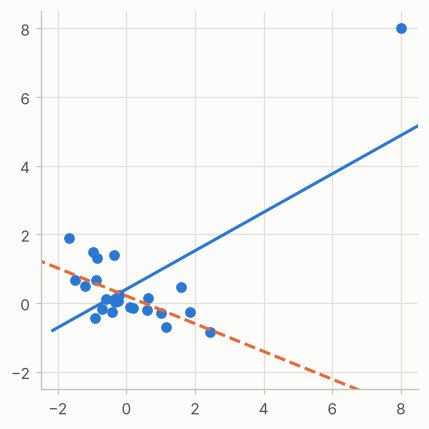

In [27]:
# BOOK CODE (Influential values): one point with a strong influence on the line
np.random.seed(5)
x = np.random.normal(size=25)
y = -x / 5 + np.random.normal(size=25)
x[0] = 8
y[0] = 8


def abline(slope, intercept, ax):
    """Calculate coordinates of a line based on slope and intercept"""
    x_vals = np.array(ax.get_xlim())
    return (x_vals, intercept + slope * x_vals)


fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(x, y)
slope, intercept, _, _, _ = linregress(x, y)
ax.plot(*abline(slope, intercept, ax))
slope, intercept, _, _, _ = linregress(x[1:], y[1:])
ax.plot(*abline(slope, intercept, ax), '--')
ax.set_xlim(-2.5, 8.5)
ax.set_ylim(-2.5, 8.5)

plt.tight_layout()
plt.show()

For the house data, the plot of the studentized residuals against the hat values with the points sized by Cook's distance (the dashed lines mark $\pm 2.5$).

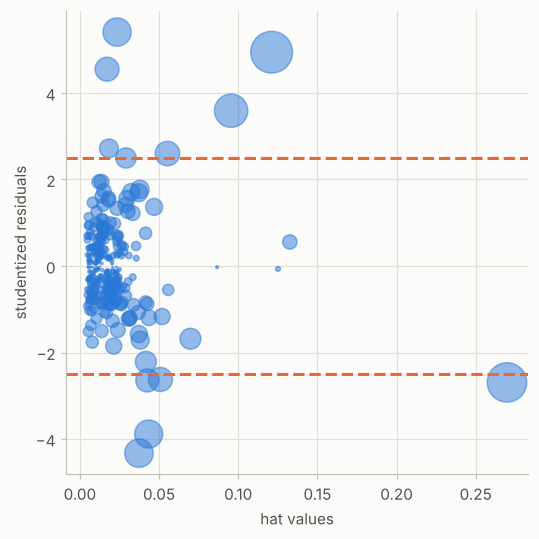

In [28]:
# BOOK CODE (Influential values): hat values, studentized residuals and Cook's distance
influence = OLSInfluence(result_98105)
fig, ax = plt.subplots(figsize=(5, 5))
ax.axhline(-2.5, linestyle='--', color='C1')
ax.axhline(2.5, linestyle='--', color='C1')
ax.scatter(influence.hat_matrix_diag, influence.resid_studentized_internal,
           s=1000 * np.sqrt(influence.cooks_distance[0]),
           alpha=0.5)

ax.set_xlabel('hat values')
ax.set_ylabel('studentized residuals')

plt.tight_layout()
plt.show()

Refitting without the records whose Cook's distance is 0.08 or more, and comparing the coefficients.

In [29]:
# BOOK CODE (Influential values): the model without the influential records
mask = [dist < .08 for dist in influence.cooks_distance[0]]
house_infl = house_98105.loc[mask]

ols_infl = sm.OLS(house_infl[outcome], house_infl[predictors].assign(const=1))
result_infl = ols_infl.fit()

pd.DataFrame({
    'Original': result_98105.params,
    'Influential removed': result_infl.params,
})

,Original,Influential removed
SqFtTotLiving,209.602346,230.052569
SqFtLot,38.933315,33.141600
Bathrooms,2282.264145,-16131.879785
Bedrooms,-26320.268796,-22887.865318
BldgGrade,130000.099737,114870.559737
const,-772549.862447,-647137.096716


**Output analysis of the influential values.**

* **The artificial example.** The 24 ordinary points have a negative trend (the dashed line), but the single point at $(8, 8)$ is so far from the others that the line fitted to all the points (solid) has a positive slope. One point with an extreme predictor value and a response that does not follow the trend has reversed the sign of the slope.
* **The house data.** The hat values have an average of 0.019 (the number of coefficients, 6, divided by the number of records, 313) and a maximum of 0.27: one sale has a very unusual combination of predictors. The plot shows 11 sales beyond the lines at $\pm 2.5$ (6 above and 5 below), the largest studentized residuals being +5.4 and -4.3; the sizes of the circles show which ones are influential (the largest Cook's distance is 0.56).
* **Removing the influential records.** Dropping the 6 sales with a Cook's distance of 0.08 or more changes the coefficients noticeably: the living area goes from 209.6 to 230.1, the bathrooms from +2,282 to -16,132 (a change of sign), the bedrooms from -26,320 to -22,888, the grade from 130,000 to 114,871 and the constant from -772,550 to -647,137. A handful of sales (2% of the data) is enough to move the coefficients like that; for the explanation of the data this is a warning, for prediction these points can often stay in.

Heteroskedasticity: the absolute residuals against the predicted values, with a LOWESS smooth line (`regplot` of seaborn).

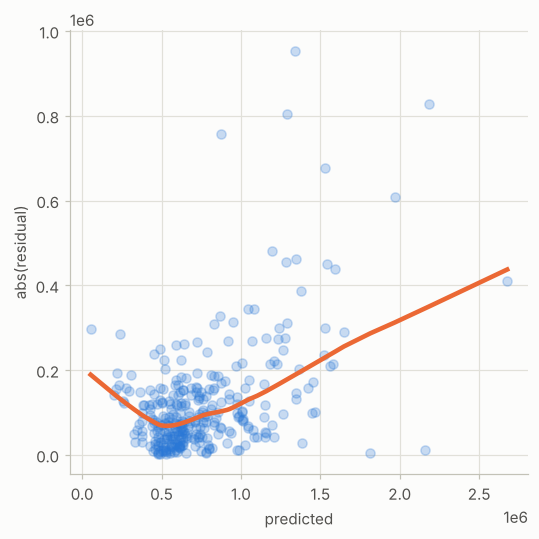

In [30]:
# BOOK CODE (Heteroskedasticity, Non-Normality, and Correlated Errors): absolute residuals against predicted values
fig, ax = plt.subplots(figsize=(5, 5))
sns.regplot(x=result_98105.fittedvalues, y=np.abs(result_98105.resid),
            scatter_kws={'alpha': 0.25},
            line_kws={'color': 'C1'},
            lowess=True, ax=ax)
ax.set_xlabel('predicted')
ax.set_ylabel('abs(residual)')

plt.tight_layout()
plt.show()

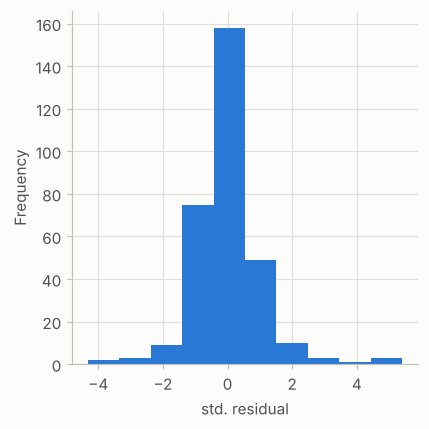

In [31]:
# BOOK CODE (Heteroskedasticity, Non-Normality, and Correlated Errors): the distribution of the standardized residuals
fig, ax = plt.subplots(figsize=(4, 4))
pd.Series(influence.resid_studentized_internal).hist(ax=ax)
ax.set_xlabel('std. residual')
ax.set_ylabel('Frequency')


plt.tight_layout()
plt.show()

Partial residual plots: one predictor (`plot_ccpr`) and all of them (`plot_ccpr_grid`).

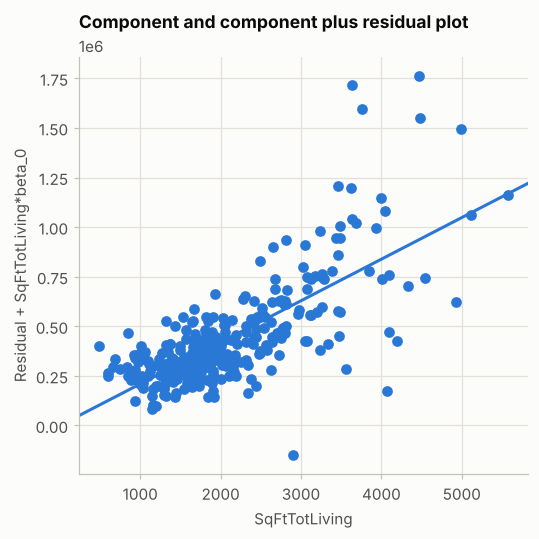

In [32]:
# BOOK CODE (Partial Residual Plots and Nonlinearity): the partial residual plot of the living area
fig, ax = plt.subplots(figsize=(5, 5))
fig = sm.graphics.plot_ccpr(result_98105, 'SqFtTotLiving', ax=ax)

plt.tight_layout()
plt.show()

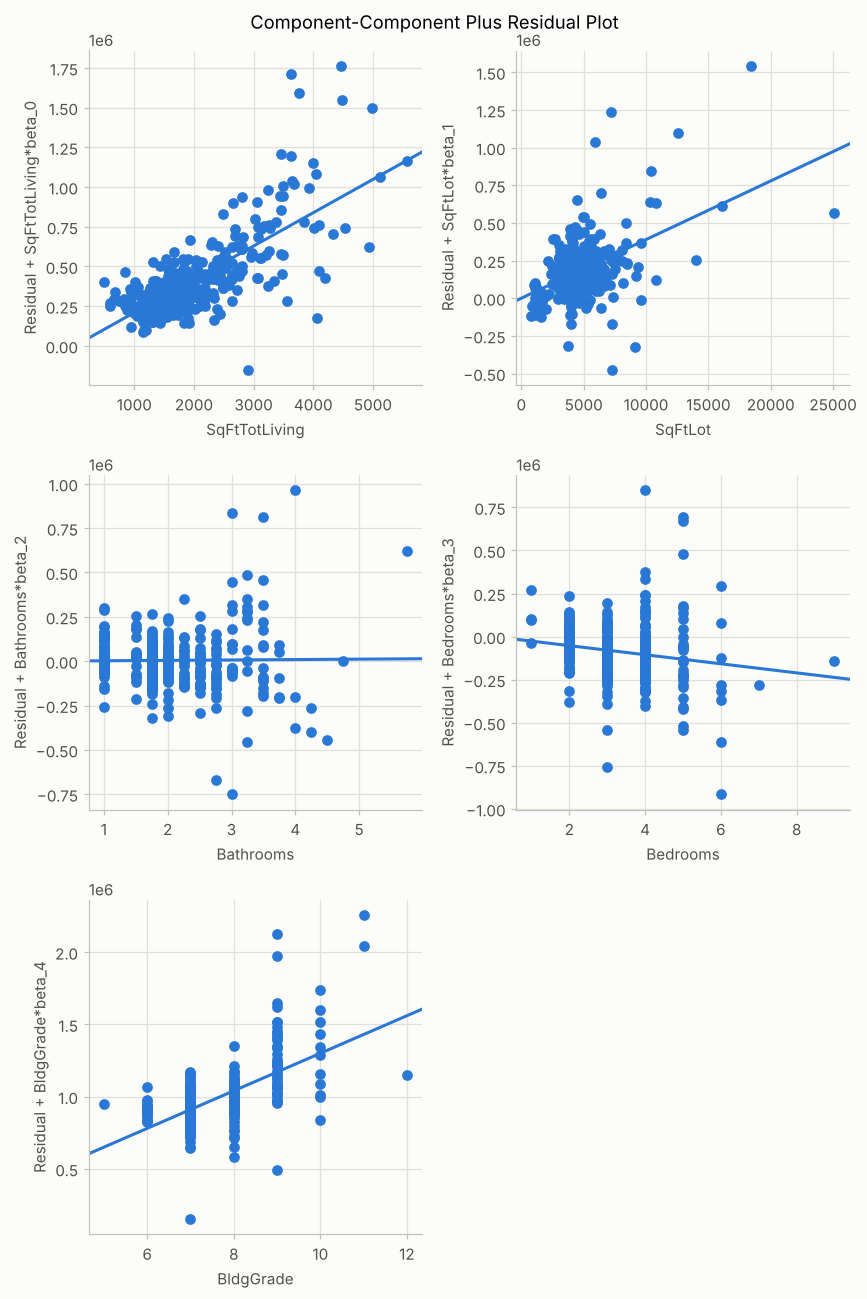

In [33]:
# BOOK CODE (Partial Residual Plots and Nonlinearity): the partial residual plots of all predictors
fig = plt.figure(figsize=(8, 12))
fig = sm.graphics.plot_ccpr_grid(result_98105, fig=fig)

**Output analysis of the residual plots.**

* **Heteroskedasticity.** In the plot of the absolute residuals against the predicted price, the smooth line is lowest for predicted prices of about 500,000 dollars and rises steadily for the more expensive houses: the typical error is larger for expensive houses, so the variance of the errors is not constant. The standard errors and tests of the summary assume that it is, so they should be treated with caution here.
* **Non-normality.** The histogram of the studentized residuals is concentrated around zero but has a long right tail (values up to 5.4), in line with the skewness and kurtosis of the summary. The usual intervals for single predictions, which rely on normal errors, are not reliable for these data.
* **Partial residual plots.** In the plot for the living area, a number of the points for the large houses (between about 3,500 and 4,500 square feet) lie well above the straight line while others lie below it, so the straight line does not describe the large houses well; the polynomial and spline fits of the next section follow the curved pattern more closely. For the bathrooms the fitted line is almost flat, for the bedrooms it falls slightly, and for the grade and the lot size it rises. The curved pattern of the living area is the motivation for the next section.

---
## 7. Polynomial and spline regression

*Book section: "Polynomial and Spline Regression" (polynomial, splines, generalized additive models). The code of the script models the nonlinear effect of the living area on the price of the houses in the zip code 98105.*

### Summary

* The relationship between the response and a predictor is often **nonlinear**; the partial residual plot of the previous section shows it for the living area. Three extensions of the linear model capture it while staying within the regression framework.
* **Polynomial regression** adds powers of a predictor (the square, the cube, ...) to the model. In `statsmodels` formulas this is done with a term such as `np.power(SqFtTotLiving, 2)`. A low-degree polynomial is simple, but it can behave badly at the edges of the data, and every added power costs one coefficient.
* **Splines** are more flexible: a spline is a series of polynomial pieces joined smoothly at fixed points called **knots**. A cubic spline has cubic polynomials between the knots with matching values and slopes at them. It is added to a formula with `bs()` (the B-spline basis), with a number of degrees of freedom that determines how many knots there are. The coefficients of the individual spline terms are not interpretable alone; the fitted curve is, and it is best displayed in the partial residual plot.
* **Generalized additive models (GAMs)** automate the search for the nonlinear shapes: $y = \beta_0 + f_1(x_1) + \dots + f_p(x_p)$ with smooth functions $f_j$ (splines) that are estimated from the data with a penalty on the roughness; the amount of smoothing is chosen by a search. The package `pygam` provides them, with `s()` for a spline term and `l()` for a linear term. The plots of the partial dependence show the shape of each term.
* The partial residual plot of a model with a nonlinear term has to be computed by hand (the function of the script) because the one of `statsmodels` only works for linear terms.

### Theory

**Polynomial regression** is linear regression on the columns $x, x^2, \dots, x^d$, so least squares applies unchanged. The columns are highly correlated, which makes the coefficients unstable (an orthogonal polynomial basis avoids this), and the interpretation of the individual coefficients is lost: the fitted curve is what matters.

**Spline basis.** A cubic spline with knots $\kappa_1 < \dots < \kappa_K$ is a function that is a cubic polynomial on each interval, with continuous value, first and second derivative at the knots. The space of such functions has dimension $K + 4$ and can be written with the **B-spline** basis $B_1(x), \dots, B_{K+4}(x)$, so that $f(x) = \sum_k c_k B_k(x)$ is again linear in the coefficients $c_k$. With `bs(x, df=6, degree=3)` there are 6 basis columns (the intercept is separate in the formula), hence $6 - 3 = 3$ interior knots, placed at quantiles of the data.

**Penalized splines and GAMs.** The additive model $y = \beta_0 + \sum_j f_j(x_j) + \varepsilon$ is fitted by minimizing $\sum_i (y_i - \hat y_i)^2 + \sum_j \lambda_j \int f_j''(x)^2\,dx$. The penalty with the smoothing parameter $\lambda_j$ discourages wiggly curves; $\lambda = 0$ is an unpenalized spline regression and a large $\lambda$ gives a straight line. The smoothing parameters are chosen by a search with a criterion such as the generalized cross-validation (GCV), which `gridsearch` of `pygam` performs. The **effective degrees of freedom** of a term measure the flexibility that it uses.

### Book code

A polynomial of degree two in the living area, added to the model of the zip code 98105.

In [34]:
# BOOK CODE (Polynomial): a quadratic term for the living area
model_poly = smf.ols(formula='AdjSalePrice ~  SqFtTotLiving + np.power(SqFtTotLiving, 2) + ' +
                     'SqFtLot + Bathrooms + Bedrooms + BldgGrade', data=house_98105)
result_poly = model_poly.fit()
print(result_poly.summary())

                            OLS Regression Results                            
Dep. Variable:           AdjSalePrice   R-squared:                       0.806
Model:                            OLS   Adj. R-squared:                  0.802
Method:                 Least Squares   F-statistic:                     211.6
Date:                Sat, 24 Oct 2026   Prob (F-statistic):          9.95e-106
Time:                        16:44:34   Log-Likelihood:                -4217.9
No. Observations:                 313   AIC:                             8450.
Df Residuals:                     306   BIC:                             8476.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                                 coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

The function `partialResidualPlot` of the script computes the partial residuals for any term by predicting with all the other predictors set to zero (it is inefficient but works for the polynomial). One line of it takes the intercept with `model.params[0]`, which relied on a `Series` falling back to the position when the label `0` does not exist; recent versions of `pandas` have removed that fallback and the line raises a `KeyError`. The cell uses `.iloc[0]` (the same value, by position) and marks the change; the same happens in the line that prints the coefficient of the square term further down.

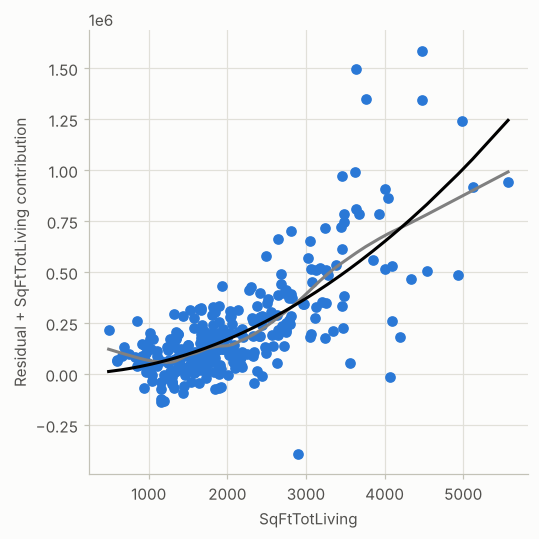

0.03879128168236203


In [35]:
# BOOK CODE (Polynomial): the partial residual plot for a model with a polynomial term
def partialResidualPlot(model, df, outcome, feature, ax):
    y_pred = model.predict(df)
    # determine columns required for model
    required = set(model.params.index).intersection(df.columns)
    required.add(feature)
    copy_df = df[list(required)].copy().astype('float')
    for c in copy_df.columns:
        if c == feature:
            continue
        copy_df.loc[:, c] = 0.0
    feature_prediction = model.predict(copy_df)
    results = pd.DataFrame({
        'feature': df[feature],
        'residual': df[outcome] - y_pred,
        'ypartial': feature_prediction - model.params.iloc[0],  # CHANGED: the script has model.params[0]
    })
    results = results.sort_values(by=['feature'])
    smoothed = sm.nonparametric.lowess(results.ypartial + results.residual,
                                       results.feature, frac=1/3)

    ax.scatter(results.feature, results.ypartial + results.residual)
    ax.plot(smoothed[:, 0], smoothed[:, 1], color='gray')
    ax.plot(results.feature, results.ypartial, color='black')
    ax.set_xlabel(feature)
    ax.set_ylabel(f'Residual + {feature} contribution')
    return ax


fig, ax = plt.subplots(figsize=(5, 5))
partialResidualPlot(result_poly, house_98105, 'AdjSalePrice', 'SqFtTotLiving', ax)

plt.tight_layout()
plt.show()
print(result_poly.params.iloc[2])  # CHANGED: the script has result_poly.params[2]

Splines: a cubic B-spline with 6 degrees of freedom in the living area, fitted with the formula term `bs()`, and its partial residual plot.

In [36]:
# BOOK CODE (Splines): a cubic spline for the living area
formula = ('AdjSalePrice ~ bs(SqFtTotLiving, df=6, degree=3) + ' +
           'SqFtLot + Bathrooms + Bedrooms + BldgGrade')
model_spline = smf.ols(formula=formula, data=house_98105)
result_spline = model_spline.fit()
print(result_spline.summary())

                            OLS Regression Results                            
Dep. Variable:           AdjSalePrice   R-squared:                       0.814
Model:                            OLS   Adj. R-squared:                  0.807
Method:                 Least Squares   F-statistic:                     131.8
Date:                Sat, 24 Oct 2026   Prob (F-statistic):          7.10e-104
Time:                        16:44:35   Log-Likelihood:                -4211.4
No. Observations:                 313   AIC:                             8445.
Df Residuals:                     302   BIC:                             8486.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                                           coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------


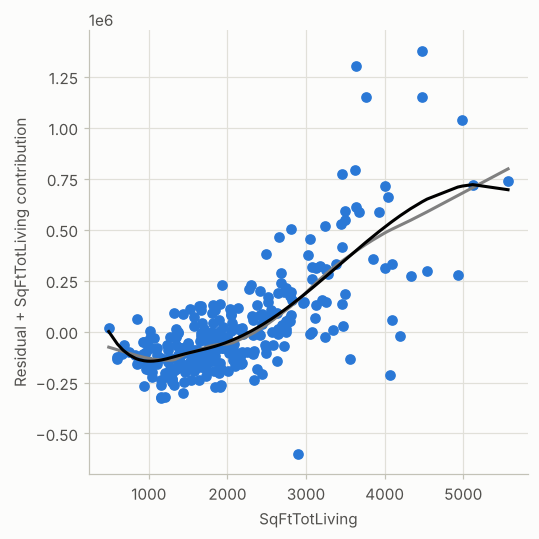

In [37]:
# BOOK CODE (Splines): the partial residual plot of the spline model
fig, ax = plt.subplots(figsize=(5, 5))
partialResidualPlot(result_spline, house_98105, 'AdjSalePrice', 'SqFtTotLiving', ax)

plt.tight_layout()
plt.show()

Generalized additive model: a spline term with 12 basis functions for the living area (`s(0, n_splines=12)`) and linear terms for the other four predictors (`l(1)` to `l(4)`). `gridsearch` chooses the smoothing parameter. The script calls it without further arguments, which draws a progress bar with the elapsed time; the cell passes `progress=False` (marked `# CHANGED`) so that the saved output does not depend on the speed of the machine.

In [38]:
# BOOK CODE (Generalized Additive Models): the GAM
predictors = ['SqFtTotLiving', 'SqFtLot', 'Bathrooms',
              'Bedrooms', 'BldgGrade']
outcome = 'AdjSalePrice'
X = house_98105[predictors].values
y = house_98105[outcome]

# model
gam = LinearGAM(s(0, n_splines=12) + l(1) + l(2) + l(3) + l(4))
gam.gridsearch(X, y, progress=False)  # CHANGED: the script has gam.gridsearch(X, y), which draws a progress bar
print(gam.summary())

LinearGAM                                                                                                 
=============================================== ==========================================================
Distribution:                        NormalDist Effective DoF:                                      7.6772
Link Function:                     IdentityLink Log Likelihood:                                 -4213.0332
Number of Samples:                          313 AIC:                                             8443.4209
                                                AICc:                                            8443.9746
                                                GCV:                                      30838885095.1715
                                                Scale:                                         171698.5198
                                                Pseudo R-Squared:                                   0.8117
Feature Function                  Lam

 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 



The partial dependence of each term with a 95% band (dashed).

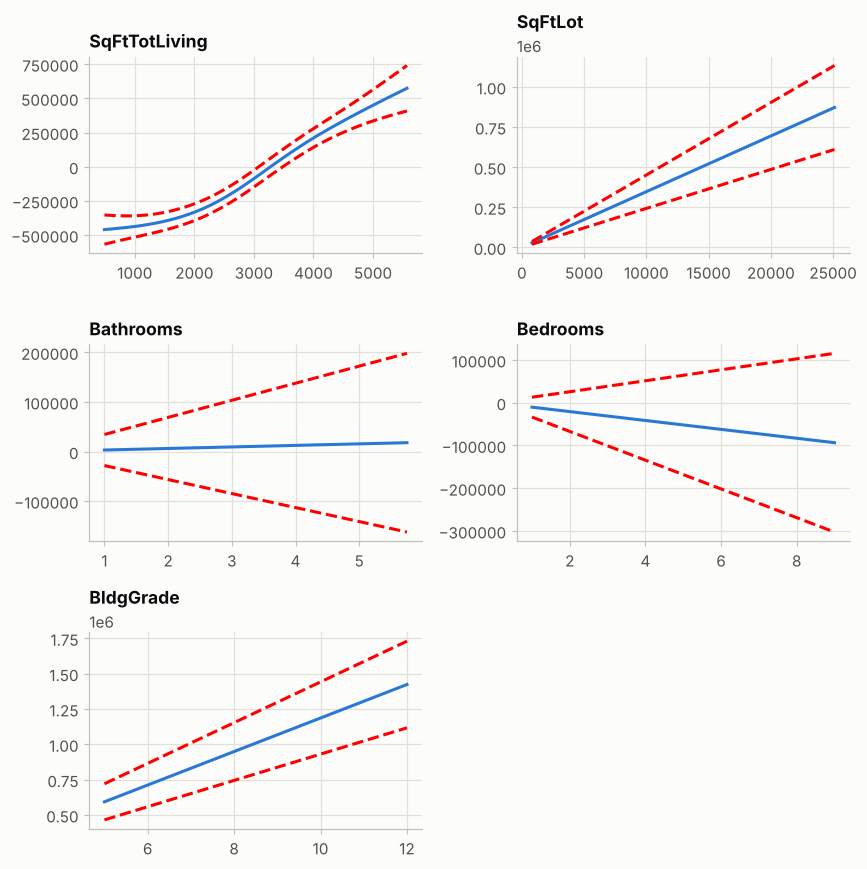

In [39]:
# BOOK CODE (Generalized Additive Models): the partial dependence plots
fig, axes = plt.subplots(figsize=(8, 8), ncols=2, nrows=3)

titles = ['SqFtTotLiving', 'SqFtLot', 'Bathrooms', 'Bedrooms', 'BldgGrade']
for i, title in enumerate(titles):
    ax = axes[i // 2, i % 2]
    XX = gam.generate_X_grid(term=i)
    ax.plot(XX[:, i], gam.partial_dependence(term=i, X=XX))
    ax.plot(XX[:, i], gam.partial_dependence(term=i, X=XX, width=.95)[1], c='r', ls='--')
    ax.set_title(titles[i])

axes[2][1].set_visible(False)

plt.tight_layout()
plt.show()

**Output analysis.**

* **The polynomial.** The square of the living area has a coefficient of 0.0388 ($p < 0.001$) and the linear term becomes insignificant ($p = 0.893$), as the two columns are strongly correlated; the condition number rises to 7.4e+07. The R-squared goes from 0.795 (linear model, section 6) to 0.806 and the AIC from 8,464 to 8,450. The line `print(result_poly.params.iloc[2])` prints the coefficient of the square, 0.0388. In the partial residual plot the polynomial (black) is a convex curve that stays close to the smooth line (gray) up to about 3,500 square feet and rises above it for the largest houses.
* **The spline.** The cubic spline with 6 degrees of freedom has an R-squared of 0.814 (adjusted 0.807) and the AIC 8,445. The individual spline coefficients have very large standard errors and are not interpretable; the curve in the partial residual plot is. It is almost flat or slightly decreasing below about 1,200 square feet, rises between about 2,000 and 4,500, and levels off for the largest houses, following the smooth line more closely than the polynomial does.
* **The GAM.** The model has an effective number of degrees of freedom of 7.68, a pseudo R-squared of 0.8117 and an AIC of 8,443 as computed by `pygam` (which may not be on the same scale as the `statsmodels` AICs above). The grid search chose the same smoothing parameter (15.85) for all the terms; the spline term of the living area uses 4.3 effective degrees of freedom. The partial dependence plot of the living area is S-shaped, rising steeply between about 2,000 and 4,000 square feet; the lot size and the grade are rising straight lines, and the bathrooms and the bedrooms have bands that contain zero (no clear effect).
* **The warnings.** `pygam` prints that the p-values of its summary are known to be much smaller than they should be, and warns that mixing splines and linear terms can make p-values appear significant when they are not; the summary table should not be used for tests. The last line `None` is the value returned by `gam.summary()`, which prints the table itself, shown by the `print` around it.

---
## 8. Additional material of the official repository: regularization (the lasso)

*This section is not part of the book chapter: the official script has a final block labelled "Additional material - not in book". It is reproduced here for completeness.*

### Summary

* **Regularization** fits a regression with many predictors while keeping the coefficients small, by adding a penalty on their size to the least squares criterion. The **lasso** penalizes the sum of the absolute values of the coefficients, which shrinks the coefficients and sets some of them exactly to zero: it does a variable selection and a fit at the same time. **Ridge regression** penalizes the sum of the squares of the coefficients, which shrinks them but keeps them all.
* The strength of the penalty is a parameter (called `alpha` in scikit-learn). With a very small `alpha` the lasso is ordinary least squares; with a very large one all coefficients are zero. The value is chosen by cross-validation (`LassoCV`).
* The script fits the lasso to all the predictors of the house data, draws the coefficients as a function of `alpha` (the **regularization path**) and marks the value chosen by 5-fold cross-validation.

### Theory

**The lasso criterion.** In scikit-learn the lasso minimizes
$$\frac{1}{2n}\sum_{i=1}^n (y_i - x_i^\top b)^2 + \alpha \sum_{j=1}^p |b_j| ,$$
and ridge regression the same with $\alpha\sum_j b_j^2$ (scikit-learn uses a differently scaled penalty for ridge, without the factor $1/2n$). The penalty is not applied to the intercept. Because the penalty compares the sizes of the coefficients, the predictors should be put on the same scale (for example standardized) first; the script has a line for this that is commented out, so the coefficients below are on the original scales of the variables, and `alpha` acts on them unevenly.

**Why the lasso gives zeros.** The constraint region $\sum_j |b_j| \le t$ has corners on the axes; the contours of the least squares criterion often touch the region at a corner, where some coefficients are zero. The squared penalty of ridge regression has a round region and no corners.

**Choice of alpha.** In $k$-fold cross-validation the lasso is fitted for a grid of values of `alpha` on $k-1$ folds, the error is computed on the remaining fold, and the `alpha` with the lowest average error is kept (`LassoCV`).

### Book code

The house data are read again and the predictors of the full model are prepared; the lasso with `alpha=10` and the ordinary regression are fitted (the script prints the fitted objects).

In [40]:
# BOOK CODE (Additional material, Regularization): the data and a first lasso fit
subset = ['AdjSalePrice', 'SqFtTotLiving', 'SqFtLot', 'Bathrooms',
          'Bedrooms', 'BldgGrade']

house = pd.read_csv(HOUSE_CSV, sep='\t')
print(house[subset].head())

predictors = ['SqFtTotLiving', 'SqFtLot', 'Bathrooms', 'Bedrooms',
              'BldgGrade', 'PropertyType', 'NbrLivingUnits',
              'SqFtFinBasement', 'YrBuilt', 'YrRenovated',
              'NewConstruction']
outcome = 'AdjSalePrice'

X = pd.get_dummies(house[predictors], drop_first=True)
X['NewConstruction'] = [1 if nc else 0 for nc in X['NewConstruction']]
columns = X.columns
# X = StandardScaler().fit_transform(X * 1.0)
y = house[outcome]

house_lm = LinearRegression()
print(house_lm.fit(X, y))

house_lasso = Lasso(alpha=10)
print(house_lasso.fit(X, y))

   AdjSalePrice  SqFtTotLiving  SqFtLot  Bathrooms  Bedrooms  BldgGrade
1      300805.0           2400     9373       3.00         6          7
2     1076162.0           3764    20156       3.75         4         10
3      761805.0           2060    26036       1.75         4          8
4      442065.0           3200     8618       3.75         5          7
5      297065.0           1720     8620       1.75         4          7
LinearRegression()
Lasso(alpha=10)


The regularization path: the coefficients for `alpha` from 0.001 to 10 million, and the value chosen by cross-validation (the vertical line). (The script defines `LassoLars` and `LassoLarsCV` first and then overwrites the choice with `Lasso` and `LassoCV`.)

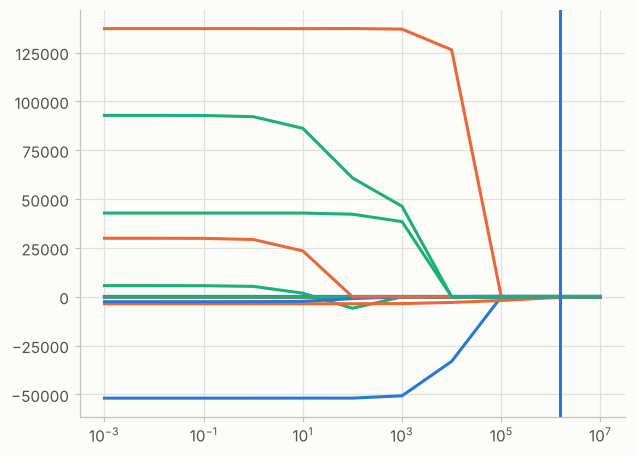

In [41]:
# BOOK CODE (Additional material, Regularization): the regularization path
Method = LassoLars
MethodCV = LassoLarsCV
Method = Lasso
MethodCV = LassoCV

alpha_values = []
results = []
for alpha in [0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000, 1000000, 10000000]:
    model = Method(alpha=alpha)
    model.fit(X, y)
    alpha_values.append(alpha)
    results.append(model.coef_)
modelCV = MethodCV(cv=5)
modelCV.fit(X, y)
ax = pd.DataFrame(results, index=alpha_values, columns=columns).plot(logx=True, legend=False)
ax.axvline(modelCV.alpha_)
plt.show()

In [42]:
# BOOK CODE (Additional material, Regularization): the coefficients at the alpha chosen by cross-validation
pd.DataFrame({
    'name': columns,
    'coef': modelCV.coef_,
})

,name,coef
0,SqFtTotLiving,289.048846
1,SqFtLot,0.029471
2,Bathrooms,0.000000
3,Bedrooms,0.000000
4,BldgGrade,0.000000
5,NbrLivingUnits,0.000000
6,SqFtFinBasement,3.316479
7,YrBuilt,-0.000000
8,YrRenovated,45.727472
9,NewConstruction,0.000000


**Output analysis.**

* **The printed objects.** `print(house_lm.fit(X, y))` prints `LinearRegression()` and the lasso `Lasso(alpha=10)`: the representation of the fitted estimators, not their coefficients.
* **The path.** For `alpha` up to about 1 the coefficients are the same as in ordinary least squares; as `alpha` grows they shrink and reach zero one after the other, until all of them are zero near $10^6$ to $10^7$. The vertical line is the `alpha` chosen by 5-fold cross-validation, at roughly $10^6$.
* **The chosen model.** At that value only four coefficients are not zero: the living area (289.05), the lot size (0.029), the finished basement (3.32) and the year of renovation (45.73). The grade, the bathrooms, the bedrooms and the year built, which matter in all the earlier models, are set to zero. This most likely comes from the scales: the predictors are not standardized (the line of the script that does it is commented out), and the penalty on the absolute value of a coefficient depends on the unit of its variable. Variables with large numeric values (such as the living area and the years) have small coefficients that are penalized little, whereas the grade has a coefficient of more than 100,000 dollars per unit and is penalized heavily. With the predictors standardized, the selection would be different.

---
## Chapter summary

**Regression models an outcome as a function of predictors**, to predict it and to explain it. Simple regression fits a line by **least squares**; multiple regression extends it to many predictors, assessed by the RMSE, the R-squared, the $t$ statistics of the coefficients and, for the error on new data, by **cross-validation**. **Stepwise selection** with a criterion such as the AIC chooses a parsimonious set of predictors; **weighted regression** changes the importance of the records. A prediction needs an interval (**confidence** for the mean, **prediction** interval for a single record, wider) and should not **extrapolate** beyond the data. **Factor variables** enter as dummy variables with a reference level, and factors with many levels are best combined. The coefficients depend on the other predictors in the model (**correlated predictors**, **confounding**), and **interactions** let the effect of a predictor depend on another variable. **Diagnostics** look for **outliers**, **influential values**, heteroskedasticity, non-normality and nonlinearity (**partial residual plots**), which **polynomials, splines and generalized additive models** can capture. The lasso of the additional material shrinks coefficients and selects variables.

### Key takeaways

1. The least squares line of the lung data has a slope of -4.185 PEFR units per year of exposure, and the residuals are large (up to 200 to 300 units), so the line explains only part of the variation between workers (section 1).
2. The house price model with five predictors has an R-squared of 0.54 and an RMSE of 261,220 dollars on the data it was fitted to; the full model reaches 0.595, and the stepwise AIC search keeps eight columns of twelve (section 2).
3. A coefficient depends on the other variables in the model: the bedrooms are -51,947 with the living area and +27,151 without it, and the single-family indicator changes from -84,678 to +19,324 when the location is added (sections 4 and 5).
4. A factor with 80 levels (zip codes) was reduced to 5 groups; the interaction with the living area shows that a square foot is worth 114.8 dollars in the cheapest group and 341.4 in the most expensive one (sections 4 and 5).
5. One extreme point can reverse a slope in the artificial example, and removing 6 of 313 influential sales changes most coefficients of the zip code 98105 by 10% to 15% and flips the sign of the bathrooms (section 6).
6. The residuals are heteroskedastic and heavy-tailed, so the standard errors and the normal prediction intervals of the summary should be used with caution (section 6).
7. The effect of the living area is nonlinear; a quadratic term, a cubic spline and a GAM all improve the fit (AIC from 8,464 to about 8,445) (section 7).
8. The lasso depends on the scale of the predictors: on unstandardized data it keeps the living area and drops the grade (section 8).

### Book vs. library notes

The official code of the chapter ran in this notebook with the versions printed by the setup cell, with the changes below. Everything else, in particular what the plots look like, may differ in other versions of the libraries.

* **Paths.** The official script finds its data folder with a helper module; here `DATA` comes from the setup cell, which also downloads the files from the official repository if they are missing.
* **Changes that are needed (`# CHANGED`).** (1) `model.params[0]` in `partialResidualPlot` and `result_poly.params[2]`: in recent versions of `pandas` a `Series` with a text index no longer falls back to the position for an integer key, and these lines raise a `KeyError`; the cells use `.iloc[0]` and `.iloc[2]`, which give the same values. (2) `gam.gridsearch(X, y)` draws a progress bar with the elapsed time; the cell passes `progress=False`, which does not change the fitted model.
* **The backend of Matplotlib.** Importing `dmba` prints `no display found. Using non-interactive Agg backend` and selects that backend when no display is found (a server, a background run). Then no figure is shown in a notebook, so the cell after the imports, which is not in the book, runs `%matplotlib inline`. On a computer with a display the message does not appear.
* **Two libraries outside the standard installation.** `pygam` and `dmba` have to be installed (`pip install pygam dmba`); the setup cell does it when they are missing (a fresh environment, or Google Colab, may not have them). The `wage` data set that the script imports from `pygam.datasets` is not used.
* **The summaries of `statsmodels` print the date and the time** of the run, so the saved output changes each time the notebook is executed.
* **`pygam`.** The summary warns that its p-values are unreliable (a known issue of the package), and `print(gam.summary())` prints the table and then `None`.
* **The zip groups.** The binning with `pd.qcut` gives groups of equal numbers of zip codes (16 each), which differs from the R code of the book; the script says that the results differ because of it.
* **Seeds.** The script sets a seed only for the artificial data of the influential values (`np.random.seed(5)`); the other code is deterministic (least squares, `LassoCV` with the default 5 folds without shuffling).
* **`pandas` 3.** Text columns have the dtype `str` (earlier `object`); `pd.get_dummies` without `dtype` returns Boolean columns, which scikit-learn accepts.
* **Plot style.** The setup cell sets the `Matplotlib` style globally, so the figures of the book code also have this notebook's style, not the default one.
* **License.** The code and the data of the official repository are under the GNU General Public License v3. This repository does not redistribute the data: the notebook downloads it at run time, and the `data` folder is ignored by git.

---
## References

* Bruce, P., Bruce, A. and Gedeck, P. (2020). *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, 2nd edition. O'Reilly Media.
* Official code and data of the book: `gedeck/practical-statistics-for-data-scientists` on GitHub (GNU General Public License v3).
* The versions of `NumPy`, `pandas`, `SciPy`, `statsmodels`, `scikit-learn`, `pygam` and `Matplotlib` are printed by the setup cell.